# Step 5: Find landslides in fresh Nepal imagery

Goal: point the trained model at real Sentinel-2 imagery it has never seen, and find the landslides from the **26–28 September 2024 monsoon storm** in central Nepal.

The test area is around the **Jhyaple Khola landslide** on the Tribhuvan Rajpath highway (27.7115° N, 85.2024° E). Early on 28 September 2024 it buried two buses and killed 35 people. Hundreds of other landslides hit the surrounding hills the same weekend.

What this notebook does:
1. Downloads a clear **before** image (winter 2023–24) and a clear **after** image (winter 2024–25) from Microsoft's Planetary Computer. It's free and needs no account.
2. Downloads elevation data and calculates slope, the same extra layers the model trained on.
3. Runs the model on both images and keeps landslides that show up only in the *after* image. Those are the new ones.
4. Saves the results as map files you can use in Step 6.

**Before running**, open a terminal tab (not the one running JupyterLab) and install the mapping libraries:
```
conda activate geoai
conda install -c conda-forge pystac-client planetary-computer odc-stac rasterio geopandas -y
```
You also need `landslide_unet.pt` and `model_config.json` from Step 4 in `~/geoai/`.

In [1]:
import os
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"

import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import planetary_computer
import pystac_client
import odc.stac
import rasterio
from rasterio import features
import geopandas as gpd
from pyproj import Transformer
from shapely.geometry import shape

ROOT = Path.home() / "geoai"
OUT_DIR = ROOT / "outputs"
OUT_DIR.mkdir(exist_ok=True)

if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
print("Running on:", device)

Running on: mps


## Load the trained model
The U-Net has to be defined exactly the same way as in Step 4 so the saved weights fit into it.

In [2]:
def double_conv(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
        nn.Conv2d(c_out, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
    )

class UNet(nn.Module):
    def __init__(self, in_ch=14, base=32):
        super().__init__()
        c1, c2, c3, c4, c5 = base, base * 2, base * 4, base * 8, base * 16
        self.pool = nn.MaxPool2d(2)
        self.enc1, self.enc2 = double_conv(in_ch, c1), double_conv(c1, c2)
        self.enc3, self.enc4 = double_conv(c2, c3), double_conv(c3, c4)
        self.bottleneck = double_conv(c4, c5)
        self.up4, self.dec4 = nn.ConvTranspose2d(c5, c4, 2, stride=2), double_conv(c5, c4)
        self.up3, self.dec3 = nn.ConvTranspose2d(c4, c3, 2, stride=2), double_conv(c4, c3)
        self.up2, self.dec2 = nn.ConvTranspose2d(c3, c2, 2, stride=2), double_conv(c3, c2)
        self.up1, self.dec1 = nn.ConvTranspose2d(c2, c1, 2, stride=2), double_conv(c2, c1)
        self.head = nn.Conv2d(c1, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))
        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.head(d1)

config = json.loads((ROOT / "model_config.json").read_text())
model = UNet(in_ch=config["in_channels"], base=config["base"]).to(device)
model.load_state_dict(torch.load(ROOT / "landslide_unet.pt", map_location=device))
model.eval()
print("Loaded model. Validation F1 from Step 4:", config["val_f1"], "| threshold:", config["threshold"])

Loaded model. Validation F1 from Step 4: 0.739 | threshold: 0.75


## Pick the area and dates
The box is about 10 × 10 km around Jhyaple Khola. To look somewhere else in Nepal, change the center point. Keep the box small (`HALF_SIZE_DEG` of 0.1 or less) so the download stays quick.

The dates are dry-season windows, when the sky over Nepal is clearest. During the monsoon it is almost always cloudy.

In [3]:
SITES = {
    "jhyaple_khola": dict(
        name="Jhyaple Khola landslide, Tribhuvan Rajpath (28 Sep 2024 storm)",
        lat=27.7115, lon=85.2024,
        before="2023-10-15/2024-02-15", after="2024-10-15/2025-02-15"),
    "melamchi": dict(
        name="Melamchi flood and debris flow, Sindhupalchok (June 2021)",
        lat=27.83, lon=85.58,
        before="2020-10-15/2021-02-15", after="2021-10-15/2022-02-15"),
    "jajarkot": dict(
        name="Jajarkot earthquake epicenter (3 Nov 2023)",
        lat=28.848, lon=82.187,
        before="2023-10-01/2023-11-02", after="2023-11-05/2024-02-15"),
}

SITE = "jhyaple_khola"        # <- change this to "melamchi" or "jajarkot"

s = SITES[SITE]
SITE_NAME = s["name"]
CENTER_LAT, CENTER_LON = s["lat"], s["lon"]
BEFORE_DATES, AFTER_DATES = s["before"], s["after"]
HALF_SIZE_DEG = 0.05          # about 5 km in each direction
MAX_TILE_CLOUD = 20           # skip satellite passes that are more than 20% cloudy overall

BBOX = (CENTER_LON - HALF_SIZE_DEG, CENTER_LAT - HALF_SIZE_DEG,
        CENTER_LON + HALF_SIZE_DEG, CENTER_LAT + HALF_SIZE_DEG)
UTM_ZONE = int((CENTER_LON + 180) // 6) + 1
CRS = f"EPSG:{32600 + UTM_ZONE}"
print(SITE_NAME, "| area:", BBOX, "| projection:", CRS)

Area: (85.1524, 27.6615, 85.2524, 27.7615) | projection: EPSG:32645


## Connect to the imagery catalog
A few details matter here:
- **No B10 band.** The cloud-corrected Sentinel-2 product (called *L2A*) drops band B10, the cirrus band. The model expects 14 layers, so B10 gets filled with an "average" value. B10 mostly shows high thin clouds, so this costs very little.
- **Clouds.** Each image comes with a scene classification layer (`SCL`) that marks clouds, cloud shadows and snow. We use it to pick the clearest day and to ignore cloudy pixels.

In [4]:
catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)

In [5]:
S2_BANDS = ["B01", "B02", "B03", "B04", "B05", "B06", "B07", "B08", "B09", "B11", "B12"]
MODEL_BAND_ORDER = ["B01", "B02", "B03", "B04", "B05", "B06", "B07", "B08", "B09", None, "B11", "B12"]  # None = B10
BAD_SCL = [0, 1, 3, 8, 9, 10, 11]   # no data, saturated, cloud shadow, clouds, cirrus, snow

def find_clearest_day(dates, max_candidates=6):
    items = list(catalog.search(collections=["sentinel-2-l2a"], bbox=BBOX, datetime=dates,
                                query={"eo:cloud_cover": {"lt": MAX_TILE_CLOUD}}).items())
    if not items:
        raise ValueError(f"No Sentinel-2 images found for {dates}. Try a wider date range or raise MAX_TILE_CLOUD.")
    by_day = {}
    for it in items:
        by_day.setdefault(it.datetime.date(), []).append(it)
    candidates = sorted(by_day, key=lambda d: np.mean([it.properties["eo:cloud_cover"] for it in by_day[d]]))
    best_day, best_bad = None, 2.0
    for day in candidates[:max_candidates]:
        scl = odc.stac.load(by_day[day], bands=["SCL"], bbox=BBOX, crs=CRS, resolution=60,
                            groupby="solar_day", dtype="uint16", nodata=0)["SCL"].values[0]
        bad = np.isin(scl, BAD_SCL).mean()
        print(f"   {day}: {bad:.0%} of the area is cloud, shadow or missing")
        if bad < best_bad:
            best_day, best_bad = day, bad
    print(f"   -> using {best_day}")
    return best_day, by_day[best_day]

def load_scene(items):
    ds = odc.stac.load(items, bands=S2_BANDS + ["SCL"], bbox=BBOX, crs=CRS, resolution=10,
                       groupby="solar_day", dtype="uint16", nodata=0,
                       resampling={"*": "bilinear", "SCL": "nearest"})
    return ds.isel(time=0)

def stretch(a, valid=None):
    vals = a[valid] if valid is not None and valid.any() else a
    lo, hi = np.percentile(vals, (2, 98))
    return np.clip((a - lo) / (hi - lo + 1e-6), 0, 1)

def true_color(ds):
    rgb = [ds[b].values.astype(np.float32) for b in ("B04", "B03", "B02")]
    valid = rgb[0] > 0
    return np.dstack([stretch(c, valid) for c in rgb])

## Download the before and after images
This looks at up to 6 of the least cloudy satellite passes in each date window, checks how cloudy *your box* actually is on each, and downloads the clearest one. It usually takes a minute or two.

BEFORE
   2024-02-11: 100% of the area is cloud, shadow or missing
   2023-10-22: 0% of the area is cloud, shadow or missing
   2023-11-26: 2% of the area is cloud, shadow or missing
   2023-11-13: 95% of the area is cloud, shadow or missing
   2023-11-16: 1% of the area is cloud, shadow or missing
   2023-11-23: 99% of the area is cloud, shadow or missing
   -> using 2023-10-22
AFTER
   2024-12-27: 96% of the area is cloud, shadow or missing
   2024-12-17: 99% of the area is cloud, shadow or missing
   2025-01-11: 100% of the area is cloud, shadow or missing
   2024-12-15: 1% of the area is cloud, shadow or missing
   2024-12-12: 98% of the area is cloud, shadow or missing
   2025-02-10: 98% of the area is cloud, shadow or missing
   -> using 2024-12-15
Image size: Shape2d(x=1003, y=1124) pixels


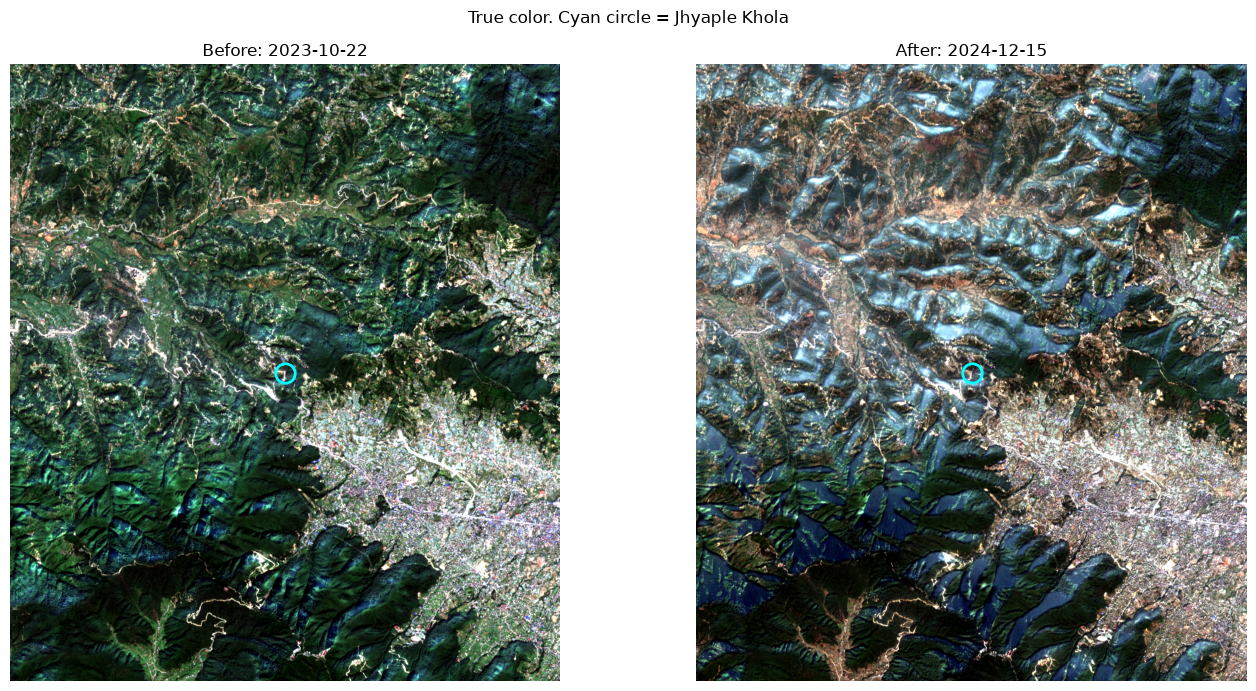

In [6]:
print("BEFORE")
before_day, before_items = find_clearest_day(BEFORE_DATES)
before = load_scene(before_items)

print("AFTER")
after_day, after_items = find_clearest_day(AFTER_DATES)
after = load_scene(after_items)

geobox = before.odc.geobox
assert after.odc.geobox.shape == geobox.shape, "Before and after grids don't line up"
print("Image size:", geobox.shape, "pixels")

left, bottom, right, top = geobox.boundingbox
EXTENT = [left, right, bottom, top]
to_utm = Transformer.from_crs("EPSG:4326", CRS, always_xy=True)
SITE_X, SITE_Y = to_utm.transform(CENTER_LON, CENTER_LAT)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, ds, day, name in [(axes[0], before, before_day, "Before"), (axes[1], after, after_day, "After")]:
    ax.imshow(true_color(ds), extent=EXTENT)
    ax.plot(SITE_X, SITE_Y, "o", mfc="none", mec="cyan", ms=14, mew=2)
    ax.set_title(f"{name}: {day}")
    ax.axis("off")
plt.suptitle("True color. Cyan circle = Jhyaple Khola")
plt.tight_layout(); plt.show()

## Elevation and slope
The model also learned from elevation and slope. We use the Copernicus 30 m elevation model, resampled onto the same 10 m grid, and compute slope from it.

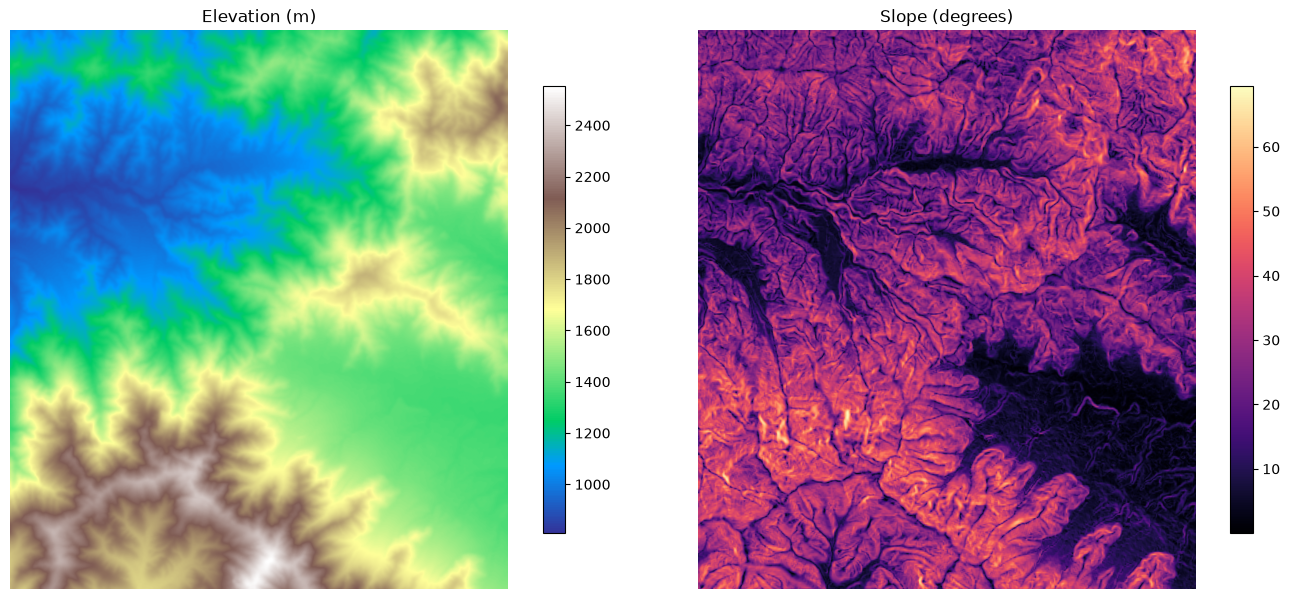

In [7]:
dem_items = list(catalog.search(collections=["cop-dem-glo-30"], bbox=BBOX).items())
dem_ds = odc.stac.load(dem_items, bands=["data"], geobox=geobox, resampling="bilinear", dtype="float32")
dem = dem_ds["data"].max(dim="time").values

def slope_degrees(dem, pixel_size=10.0):
    dy, dx = np.gradient(dem, pixel_size)
    return np.degrees(np.arctan(np.hypot(dx, dy)))

slope = slope_degrees(dem)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
im0 = axes[0].imshow(dem, cmap="terrain", extent=EXTENT); axes[0].set_title("Elevation (m)")
im1 = axes[1].imshow(slope, cmap="magma", extent=EXTENT); axes[1].set_title("Slope (degrees)")
for ax, im in zip(axes, (im0, im1)):
    plt.colorbar(im, ax=ax, shrink=0.8); ax.axis("off")
plt.tight_layout(); plt.show()

## Prepare the 14 layers the model expects
**Normalization**, briefly: the model learned from numbers on a particular scale. New imagery comes from a different processing chain, so its raw numbers aren't on that scale. To fix this, each layer is rescaled so its average is 0 and its spread is 1 over the clear pixels of this image. That is roughly what the model saw during training.

This is the weakest link in the whole pipeline. If results look off, this step is the first place to look.

In [8]:
def standardize(a, valid):
    m, s = a[valid].mean(), a[valid].std() + 1e-6
    return np.where(valid, (a - m) / s, 0).astype(np.float32)

def build_input(ds):
    valid = (ds["B02"].values > 0) & ~np.isin(ds["SCL"].values, BAD_SCL) & np.isfinite(dem)
    layers = []
    for name in MODEL_BAND_ORDER:
        if name is None:
            layers.append(np.zeros(valid.shape, np.float32))   # B10 not available: use the average value
        else:
            layers.append(standardize(ds[name].values.astype(np.float32), valid))
    layers.append(standardize(np.nan_to_num(slope), valid))
    layers.append(standardize(np.nan_to_num(dem), valid))
    return np.stack(layers), valid

x_before, valid_before = build_input(before)
x_after, valid_after = build_input(after)
print("Model input:", x_after.shape, "| clear pixels before:", f"{valid_before.mean():.0%}",
      "| after:", f"{valid_after.mean():.0%}")

Model input: (14, 1124, 1003) | clear pixels before: 100% | after: 100%


## Run the model
The model only takes 128 × 128 pixel patches, but the image is much bigger. So we slide a 128 × 128 window across it in overlapping steps and average the overlapping predictions, which avoids visible seams.

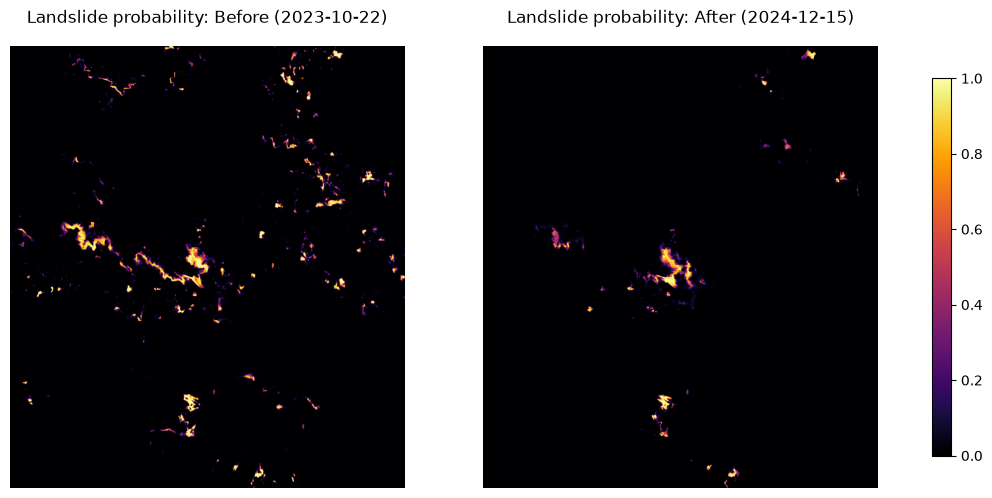

In [9]:
@torch.no_grad()
def predict_large(x, tile=128, stride=64, batch_size=16):
    C, H, W = x.shape
    H2 = max(tile, int(np.ceil((H - tile) / stride)) * stride + tile)
    W2 = max(tile, int(np.ceil((W - tile) / stride)) * stride + tile)
    xp = np.zeros((C, H2, W2), np.float32)
    xp[:, :H, :W] = x
    probs = np.zeros((H2, W2), np.float32)
    counts = np.zeros((H2, W2), np.float32)
    coords = [(r, c) for r in range(0, H2 - tile + 1, stride) for c in range(0, W2 - tile + 1, stride)]
    for i in range(0, len(coords), batch_size):
        chunk = coords[i:i + batch_size]
        xb = torch.from_numpy(np.stack([xp[:, r:r + tile, c:c + tile] for r, c in chunk])).to(device)
        pb = torch.sigmoid(model(xb)).cpu().numpy()[:, 0]
        for (r, c), p in zip(chunk, pb):
            probs[r:r + tile, c:c + tile] += p
            counts[r:r + tile, c:c + tile] += 1
    return (probs / counts)[:H, :W]

prob_before = predict_large(x_before)
prob_after = predict_large(x_after)
prob_before[~valid_before] = 0
prob_after[~valid_after] = 0

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, p, name in [(axes[0], prob_before, f"Before ({before_day})"), (axes[1], prob_after, f"After ({after_day})")]:
    im = ax.imshow(p, cmap="inferno", vmin=0, vmax=1, extent=EXTENT)
    ax.set_title(f"Landslide probability: {name}"); ax.axis("off")
plt.colorbar(im, ax=axes, shrink=0.7)
plt.show()

## Keep only the new landslides
A pixel counts as a **new landslide** if the model flags it *after* the storm, did *not* flag it before, and it was clear in both images. Tiny specks under `MIN_AREA_M2` are dropped as noise.

`THRESHOLD` starts at the value picked in Step 4. On new imagery a higher value (say 0.6–0.8) often cuts down false alarms, so try a few.

New landslides found: 15
Total new landslide area: 0.08 km²
Largest: 30,900 m²


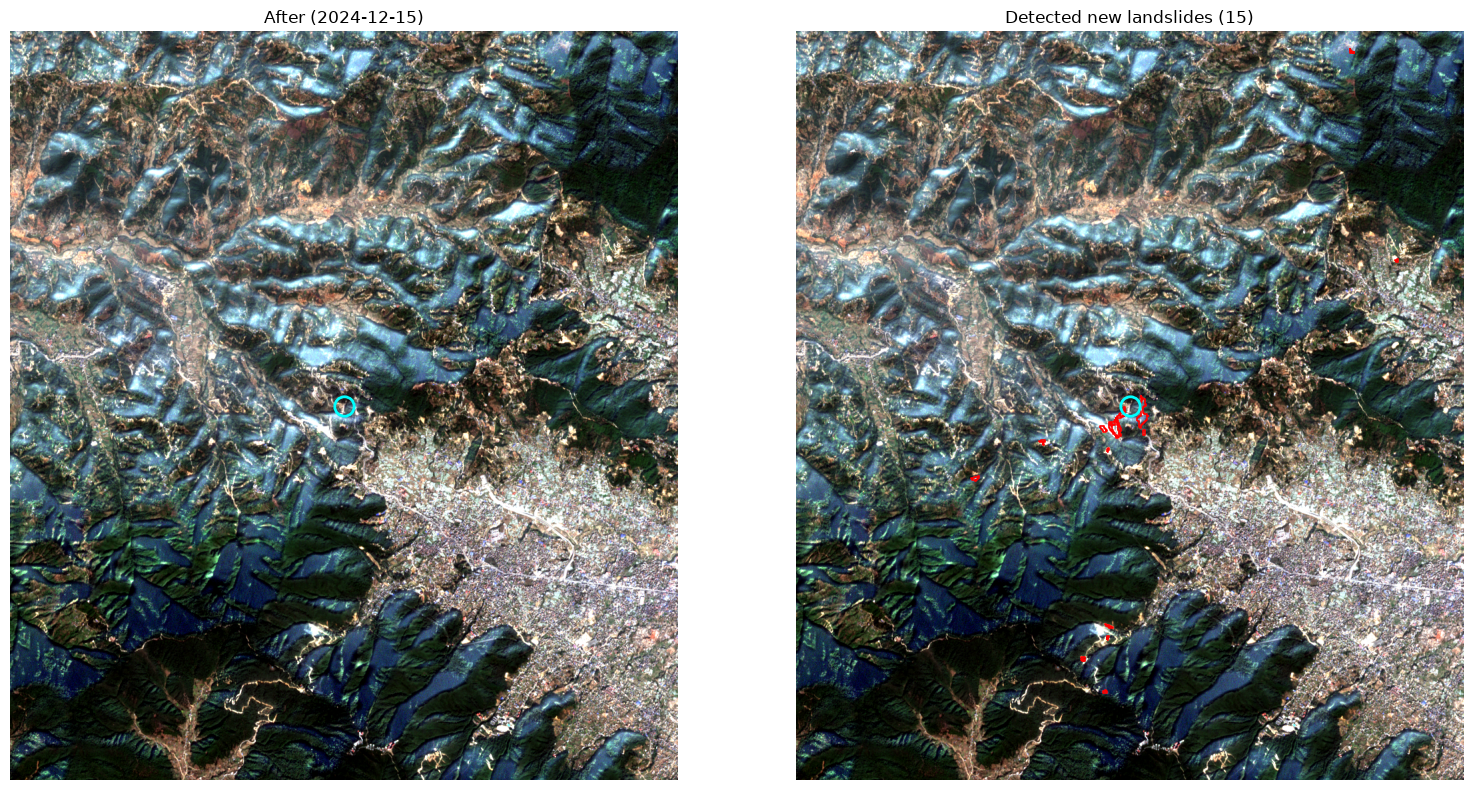

In [10]:
THRESHOLD = config["threshold"]
MIN_AREA_M2 = 1000            # 10 pixels

new_mask = (prob_after > THRESHOLD) & (prob_before <= THRESHOLD) & valid_before & valid_after

transform = geobox.affine
shapes = [shape(geom) for geom, _ in features.shapes(new_mask.astype(np.uint8), mask=new_mask, transform=transform)]
gdf = gpd.GeoDataFrame(geometry=shapes, crs=CRS)
gdf["area_m2"] = gdf.geometry.area.round(0)
gdf = gdf[gdf["area_m2"] >= MIN_AREA_M2].sort_values("area_m2", ascending=False).reset_index(drop=True)
gdf["max_prob"] = [
    float(prob_after[features.geometry_mask([g], new_mask.shape, transform, invert=True)].max())
    for g in gdf.geometry
]

print(f"New landslides found: {len(gdf)}")
print(f"Total new landslide area: {gdf['area_m2'].sum() / 1e6:.2f} km²")
if len(gdf):
    print(f"Largest: {gdf['area_m2'].iloc[0]:,.0f} m²")

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].imshow(true_color(after), extent=EXTENT); axes[0].set_title(f"After ({after_day})")
axes[1].imshow(true_color(after), extent=EXTENT)
if len(gdf):
    gdf.boundary.plot(ax=axes[1], color="red", linewidth=1.2)
axes[1].set_title(f"Detected new landslides ({len(gdf)})")
for ax in axes:
    ax.plot(SITE_X, SITE_Y, "o", mfc="none", mec="cyan", ms=14, mew=2)
    ax.set_xlim(EXTENT[0], EXTENT[1]); ax.set_ylim(EXTENT[2], EXTENT[3]); ax.axis("off")
plt.tight_layout(); plt.show()

## Zoom in on Jhyaple Khola
A 2 × 2 km window around the known landslide, so you can judge whether the model caught it.

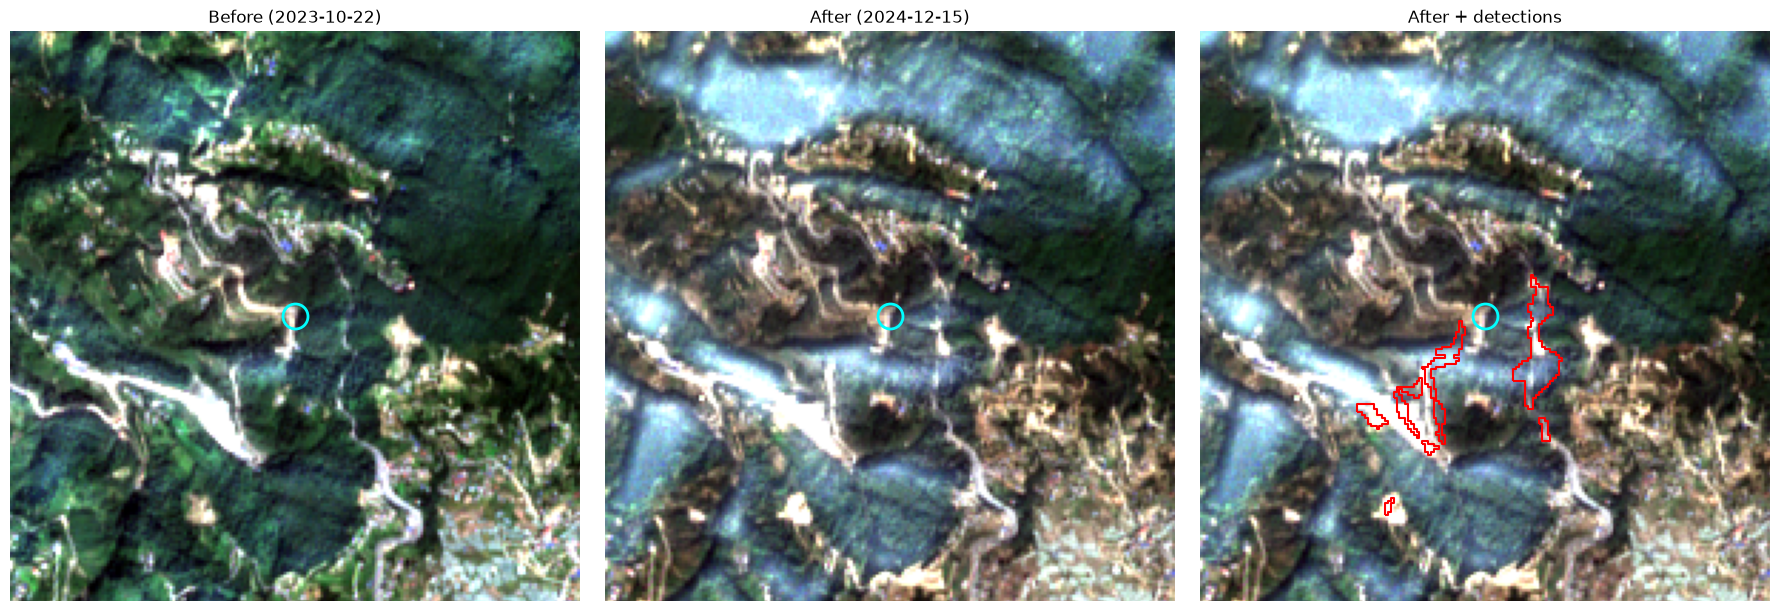

In [11]:
ZOOM_M = 1000
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(true_color(before), extent=EXTENT); axes[0].set_title(f"Before ({before_day})")
axes[1].imshow(true_color(after), extent=EXTENT); axes[1].set_title(f"After ({after_day})")
axes[2].imshow(true_color(after), extent=EXTENT); axes[2].set_title("After + detections")
if len(gdf):
    gdf.boundary.plot(ax=axes[2], color="red", linewidth=1.5)
for ax in axes:
    ax.plot(SITE_X, SITE_Y, "o", mfc="none", mec="cyan", ms=18, mew=2)
    ax.set_xlim(SITE_X - ZOOM_M, SITE_X + ZOOM_M); ax.set_ylim(SITE_Y - ZOOM_M, SITE_Y + ZOOM_M); ax.axis("off")
plt.tight_layout(); plt.show()

## Save the results
These files go in `~/geoai/outputs/`:
- `new_landslides.geojson`: one outline per detected landslide, in latitude/longitude. Step 6 puts these on a web map. You can also drag the file onto https://geojson.io to see it right away.
- `landslide_prob_after.tif`: the probability map as a GeoTIFF, which opens in QGIS or Google Earth Pro.

In [12]:
gdf_wgs84 = gdf.to_crs("EPSG:4326")
gdf_wgs84["max_prob"] = gdf_wgs84["max_prob"].round(3)
gdf_wgs84["image_date"] = str(after_day)
geojson_path = OUT_DIR / "new_landslides.geojson"
gdf_wgs84.to_file(geojson_path, driver="GeoJSON")

tif_path = OUT_DIR / "landslide_prob_after.tif"
with rasterio.open(tif_path, "w", driver="GTiff", height=prob_after.shape[0], width=prob_after.shape[1],
                   count=1, dtype="float32", crs=CRS, transform=transform, compress="deflate") as dst:
    dst.write(prob_after.astype(np.float32), 1)

summary = {
    "center": [CENTER_LAT, CENTER_LON], "bbox": BBOX,
    "before_date": str(before_day), "after_date": str(after_day),
    "threshold": THRESHOLD, "min_area_m2": MIN_AREA_M2,
    "num_new_landslides": int(len(gdf)), "total_area_km2": round(float(gdf["area_m2"].sum()) / 1e6, 3),
}
(OUT_DIR / "run_summary.json").write_text(json.dumps(summary, indent=2))
print("Saved:")
for p in (geojson_path, tif_path, OUT_DIR / "run_summary.json"):
    print("  ", p)

Saved:
   /Users/razbinkarkidoli/geoai/outputs/new_landslides.geojson
   /Users/razbinkarkidoli/geoai/outputs/landslide_prob_after.tif
   /Users/razbinkarkidoli/geoai/outputs/run_summary.json


## How to judge the results honestly
- **There's no answer key for this area**, so judge by eye. Do red outlines sit on fresh brown scars that were green in the *before* image?
- **Common false alarms:** riverbeds and sandbars that changed with the floods, new roads or construction, harvested fields, and cloud edges the cloud mask missed.
- **Common misses:** very small landslides (under a few pixels), and scars in deep shadow on steep north-facing slopes.
- **Why results can be worse than in Step 4:** the model trained on images processed differently than these, and B10 is missing. This kind of *domain shift* is a known hard problem, and it's worth naming in your write-up.

Things to try: change `THRESHOLD`, move the center to another 2024 landslide area, or compare two different after dates.

Next up, Step 6: a FastAPI backend plus a Leaflet web map that shows `new_landslides.geojson`.